In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

N=100; dimt=9000 #Tamaño de la matriz y numero de iteraciones
dt=.001; dx=.03 #Tamaños de las diferencias temporales y espaciales

#Constantes 
a = 3.8e-4  #a = 2.8e-4 
b = 6e-3    #b = 5e-3
tau = .07   #tau = .1
k = -.005

# U y V matrices(N+1,N+1) que se inicializan con valores aleatorios.
# Unew y Vnew matrices,se inicializan como ceros, para almacenar los valores de U y V durante la simulación.

U=np.random.random(size = (N+1,N+1)).astype('float64')
Unew=np.zeros([N+1,N+1],dtype=float)
V=np.random.random(size = (N+1,N+1)).astype('float64')
Vnew=np.zeros([N+1,N+1],dtype=float)


In [2]:
def show_patterns(U, ax=None):
    ax.imshow(U, cmap=plt.cm.copper,
              interpolation='bilinear',
              extent=[-1, 1, -1, 1])
    ax.set_axis_off()
    

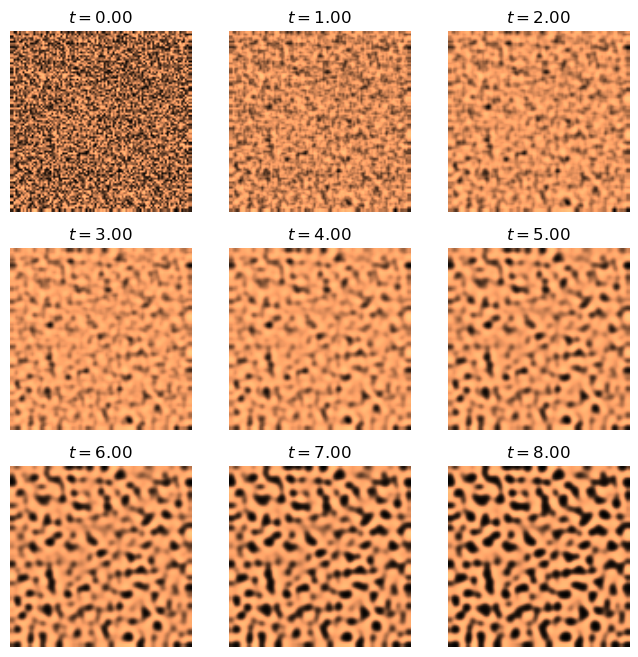

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
step_plot = dimt // 9

for n in range(dimt):
    for i in range(1,N):
        for j in range(1,N):
            
            Ucubo=U[i,j]**3
       
            laplacianU = (U[i-1,j]-2*U[i,j]+U[i+1,j])/dx**2 + (U[i,j-1]-2*U[i,j]+U[i,j+1])/dx**2
            laplacianV = (V[i-1,j]-2*V[i,j]+V[i+1,j])/dx**2 +(V[i,j-1]-2*V[i,j]+V[i,j+1])/dx**2
            
            Unew[i,j]=U[i,j]+ dt*(a*laplacianU + U[i,j] - Ucubo - V[i,j] + k)
            Vnew[i,j]=V[i,j]+ dt*(b*laplacianV + U[i,j] - V[i,j])/tau
    
 
      
    
    Unew[:,0]=Unew[:,1]
    Unew[:,N]=Unew[:,N-1]
    Unew[0,:]=Unew[1,:]
    Unew[N,:]=Unew[N-1,:]
    Vnew[:,0]=Vnew[:,1]
    Vnew[:,N]=Vnew[:,N-1]
    Vnew[0,:]=Vnew[1,:]
    Vnew[N,:]=Vnew[N-1,:]
    
    U=np.copy(Unew)
    V=np.copy(Vnew)

    
    if n % step_plot == 0 and n < 9 * step_plot:
        ax = axes.flat[n // step_plot]
        show_patterns(U, ax=ax)
        ax.set_title(f'$t={n * dt:.2f}$')

   

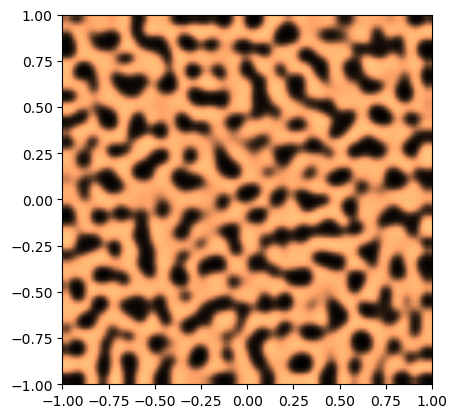

In [4]:
plt.imshow(U, cmap=plt.cm.copper,
              interpolation='bilinear',
              extent=[-1, 1, -1, 1])

